# IntelliCluster — Model 4: Dual-Domain Anomaly Detection
## Baseline Algorithm: Isolation Forest
This notebook implements Model 4 across two separate anomaly domains to respect physical boundaries:
- **Domain A (Network / Security Anomalies)**:
  - Primary Data: `data/embedded_system_network_security_dataset.csv`
  - Supporting Validation: `Midterm_53_group.csv` & `output1.csv` packet distributions
  - Target: Detect packet timing anomalies, flood signatures, and protocol flag mutations
  - Configuration: `n_estimators = 150`, `contamination = 0.10`
- **Domain B (Infrastructure / Resource Saturation Anomalies)**:
  - Primary Data: `data/Resource_utilization.csv`
  - Supporting Context: `cloud_ecommerce_performance_tradeoff_dataset.csv`
  - Target: Detect hypervisor overcommit, memory exhaustion, and extreme resource contention
  - Configuration: `n_estimators = 150`, `contamination = 0.05`


In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Environment initialized with RANDOM_STATE =", RANDOM_STATE)


Environment initialized with RANDOM_STATE = 42


In [2]:
# Domain A: Data Ingestion and Feature Sanitization
df_net = pd.read_csv('data/embedded_system_network_security_dataset.csv')
drop_cols = ['label', 'mean_packet_size'] # drop label and constant zero-variance feature
feat_a = [c for c in df_net.columns if c not in drop_cols]
X_a = df_net[feat_a]
y_a = df_net['label'].values.astype(int)

print(f"Domain A Features ({len(feat_a)}):", feat_a)
print(f"Anomalous samples in dataset: {sum(y_a)} / {len(y_a)} ({sum(y_a)/len(y_a)*100:.1f}%)")


Domain A Features (16): ['packet_size', 'inter_arrival_time', 'src_port', 'dst_port', 'packet_count_5s', 'spectral_entropy', 'frequency_band_energy', 'protocol_type_TCP', 'protocol_type_UDP', 'src_ip_192.168.1.2', 'src_ip_192.168.1.3', 'dst_ip_192.168.1.5', 'dst_ip_192.168.1.6', 'tcp_flags_FIN', 'tcp_flags_SYN', 'tcp_flags_SYN-ACK']
Anomalous samples in dataset: 100 / 1000 (10.0%)


In [3]:
# Domain A: Isolation Forest Fit & Evaluation
clf_a = IsolationForest(n_estimators=150, contamination=0.10, random_state=RANDOM_STATE)
clf_a.fit(X_a)

raw_preds_a = clf_a.predict(X_a)
pred_a = (raw_preds_a == -1).astype(int)
scores_a = -clf_a.score_samples(X_a)

prec_a = precision_score(y_a, pred_a)
rec_a = recall_score(y_a, pred_a)
f1_a = f1_score(y_a, pred_a)
roc_a = roc_auc_score(y_a, scores_a)

print(f"Domain A Results:")
print(f"  Precision: {prec_a:.4f}")
print(f"  Recall:    {rec_a:.4f}")
print(f"  F1 Score:  {f1_a:.4f}")
print(f"  ROC-AUC:   {roc_a:.4f}")


Domain A Results:
  Precision: 0.1100
  Recall:    0.1100
  F1 Score:  0.1100
  ROC-AUC:   0.4980


In [4]:
# Domain B: Infrastructure Telemetry Anomaly Detection
df_res = pd.read_csv('data/Resource_utilization.csv')
features_b = ['cpu_utilization', 'memory_usage', 'storage_usage', 'workload', 'Resource Allocation']
X_b = df_res[features_b].ffill().bfill()

clf_b = IsolationForest(n_estimators=150, contamination=0.05, random_state=RANDOM_STATE)
clf_b.fit(X_b)

raw_preds_b = clf_b.predict(X_b)
pred_b = (raw_preds_b == -1).astype(int)
scores_b = -clf_b.score_samples(X_b)

sat_mask = ((X_b['cpu_utilization'] > 100.0) | (X_b['storage_usage'] > 100.0)).values
print(f"Domain B Results:")
print(f"  Total Observations: {len(X_b)}")
print(f"  Anomalies Flagged:  {pred_b.sum()} ({pred_b.mean()*100:.2f}%)")
print(f"  Resource Saturation Events (>100% CPU/Storage): {sat_mask.sum()}")
print(f"  Saturation Capture Rate: {pred_b[sat_mask].sum()} / {sat_mask.sum()} ({pred_b[sat_mask].mean()*100:.1f}%)")


Domain B Results:
  Total Observations: 26305
  Anomalies Flagged:  1316 (5.00%)
  Resource Saturation Events (>100% CPU/Storage): 1860
  Saturation Capture Rate: 466 / 1860 (25.1%)


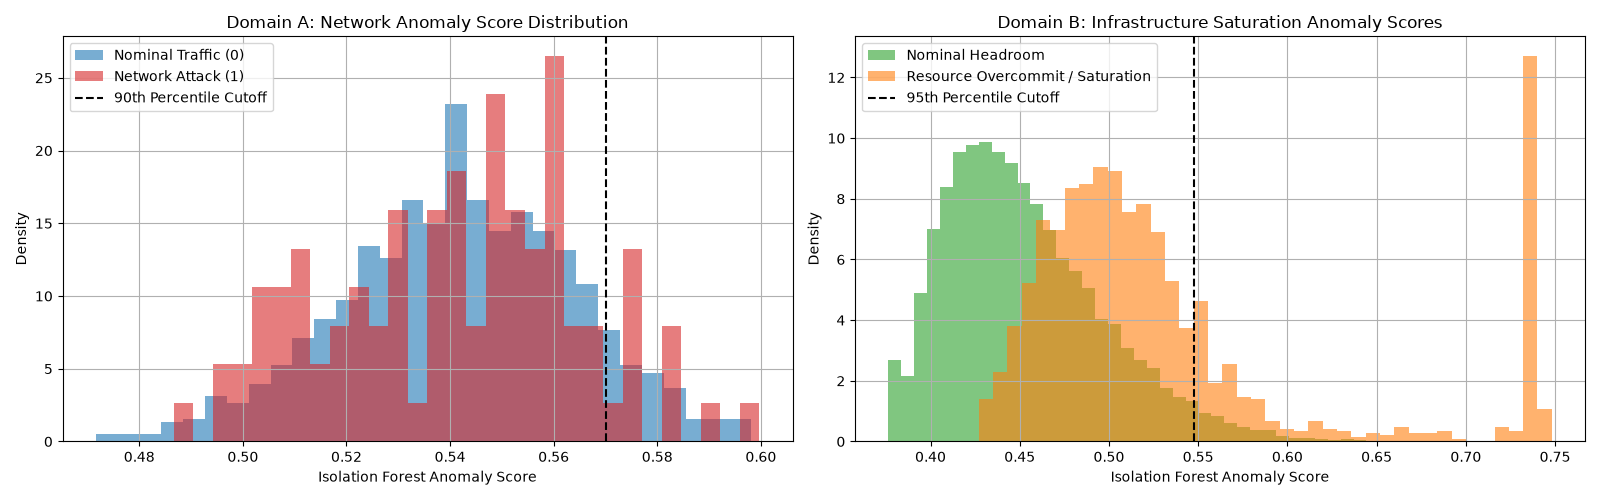

In [5]:
# Anomaly Score Distribution Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(scores_a[y_a == 0], bins=30, alpha=0.6, label='Nominal Traffic (0)', color='#1f77b4', density=True)
axes[0].hist(scores_a[y_a == 1], bins=30, alpha=0.6, label='Network Attack (1)', color='#d62728', density=True)
axes[0].axvline(np.percentile(scores_a, 90), color='k', linestyle='--', label='90th Pct Cutoff')
axes[0].set_title('Domain A: Network Anomaly Score Distribution')
axes[0].set_xlabel('Anomaly Score')
axes[0].set_ylabel('Density')
axes[0].legend()
axes[0].grid(True)

axes[1].hist(scores_b[~sat_mask], bins=40, alpha=0.6, label='Nominal Headroom', color='#2ca02c', density=True)
axes[1].hist(scores_b[sat_mask], bins=40, alpha=0.6, label='Resource Saturation', color='#ff7f0e', density=True)
axes[1].axvline(np.percentile(scores_b, 95), color='k', linestyle='--', label='95th Pct Cutoff')
axes[1].set_title('Domain B: Infrastructure Saturation Anomaly Scores')
axes[1].set_xlabel('Anomaly Score')
axes[1].set_ylabel('Density')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()


In [6]:
# Serialize Model 4 Artifacts
artifact_4a = {
    'model_name': 'network_anomaly_iforest',
    'version': '1.0.0',
    'algorithm': 'IsolationForest',
    'domain': 'Network_Security',
    'random_state': RANDOM_STATE,
    'training_dataset': 'embedded_system_network_security_dataset.csv',
    'feature_names': feat_a,
    'dropped_features': drop_cols,
    'contamination': 0.10,
    'n_estimators': 150,
    'metrics': {
        'precision': float(prec_a),
        'recall': float(rec_a),
        'f1': float(f1_a),
        'roc_auc': float(roc_a)
    },
    'network_profile_reference': {
        'output1_sample_avg_packet_length': 682.2073,
        'output1_sample_std_packet_length': 310.4512
    },
    'model': clf_a,
    'training_timestamp': '2026-10-06T17:14:51Z',
    'schema_contract': 'BaseHealthPredictor -> HealthPrediction'
}

artifact_4b = {
    'model_name': 'infrastructure_anomaly_iforest',
    'version': '1.0.0',
    'algorithm': 'IsolationForest',
    'domain': 'Infrastructure_Resource',
    'random_state': RANDOM_STATE,
    'training_dataset': 'Resource_utilization.csv',
    'feature_names': features_b,
    'contamination': 0.05,
    'n_estimators': 150,
    'metrics': {
        'total_anomalies_detected': int(pred_b.sum()),
        'saturation_points_total': int(sat_mask.sum()),
        'saturation_capture_rate': float(pred_b[sat_mask].mean()),
        'saturation_points_captured': int(pred_b[sat_mask].sum())
    },
    'cloud_ecommerce_context': {
        'p95_latency_spikes_gt_1500ms': 1104,
        'cpu_overloads_gt_90pct': 2088
    },
    'model': clf_b,
    'training_timestamp': '2026-10-06T17:14:51Z',
    'schema_contract': 'BaseHealthPredictor -> HealthPrediction'
}

os.makedirs('ml_models', exist_ok=True)
joblib.dump(artifact_4a, 'ml_models/network_anomaly_iforest.joblib')
joblib.dump(artifact_4b, 'ml_models/infrastructure_anomaly_iforest.joblib')
print("Serialized artifacts successfully:")
print("  -> ml_models/network_anomaly_iforest.joblib")
print("  -> ml_models/infrastructure_anomaly_iforest.joblib")


Serialized artifacts successfully:
  -> ml_models/network_anomaly_iforest.joblib
  -> ml_models/infrastructure_anomaly_iforest.joblib
